# Pelatihan Model Analisis Sentimen Ulasan Disney+

Antonius Vincent Jung - CACC012D6Y2282 - CAC-15

**Target:** Akurasi ≥ 85% untuk semua model

**Total Data:** 30.000 baris data

**Strategi Optimasi:**
- **LR & SVM:** Kombinasi TF-IDF word n-gram dan char n-gram, perluasan ruang pencarian hyperparameter, serta oversampling menggunakan RandomOverSampler
- **BiLSTM:** Arsitektur dua lapis Bidirectional LSTM dengan representasi gabungan GlobalMaxPooling dan GlobalAveragePooling, disertai label smoothing dan pembobotan kelas
- **Semua model:** Penanganan ketidakseimbangan kelas dan evaluasi menggunakan classification report per kelas

## Install Library

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk sastrawi wordcloud imbalanced-learn tensorflow nlpaug

## Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, string, csv, os, joblib
from collections import Counter
from io import StringIO
import requests
import warnings
warnings.filterwarnings('ignore')

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from wordcloud import WordCloud

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE, RandomOverSampler

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout, Bidirectional,
    GlobalMaxPooling1D, GlobalAveragePooling1D, Input,
    Attention, Concatenate, Conv1D, MaxPooling1D, Flatten,
    LayerNormalization, MultiHeadAttention, Add
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.regularizers import l2


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Load Dataset

In [3]:
from google.colab import drive
drive.mount('/content/drive')

raw_data_path = '/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen/disneyplus_reviews_raw.csv'
save_path = '/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen'
os.makedirs(save_path, exist_ok=True)

clean_df = pd.read_csv(raw_data_path)
print(f'Shape: {clean_df.shape}')
clean_df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (30000, 3)


,reviewId,score,content
0,974dd8bb-d007-4fef-bc07-5bdf21475226,1,"Udah beli paket dari XL, saat log in kode OTP ..."
1,0c9f7e33-3fb2-432c-8760-cd0564aae4a5,2,"Tambah lama, tambah ribet. sudah beli premium ..."
2,afdf6a08-2b68-459c-98a3-033738bb2f52,1,tolong dong aku udah berlangganan melalui myte...
3,d168a07f-fdf9-4d46-a16f-a3f3f9c800ba,1,udah beli premium yg katanya bisa untuk bebera...
4,e2599e40-ef84-4239-b13e-6b926b856511,1,Ternyata aplikasi nya beneran jelek ya. Baru a...


## Data Understanding

In [4]:
print(clean_df.info())
print('\nMissing values:')
print(clean_df.isnull().sum())
print('\nDistribusi panjang teks:')
clean_df['text_len'] = clean_df['content'].astype(str).apply(len)
print(clean_df['text_len'].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   reviewId  30000 non-null  object
 1   score     30000 non-null  int64 
 2   content   30000 non-null  object
dtypes: int64(1), object(2)
memory usage: 703.3+ KB
None

Missing values:
reviewId    0
score       0
content     0
dtype: int64

Distribusi panjang teks:
count    30000.000000
mean        85.640600
std         83.874106
min          1.000000
25%         27.000000
50%         61.000000
75%        116.000000
max        500.000000
Name: text_len, dtype: float64


## Slang Words Dictionary

In [5]:
slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "plisss": "tolong", "bgttt": "banget", "indo": "indonesia", "bgtt": "banget", "ad": "ada", "rv": "redvelvet", "plis": "tolong", "pls": "tolong", "cr": "sumber", "cod": "bayar ditempat", "adlh": "adalah", "afaik": "as far as i know", "ahaha": "haha", "aj": "saja", "ak": "saya", "alay": "norak", "alow": "halo", "ancur": "hancur", "anjrit": "anjing", "anter": "antar", "apasih": "apa sih", "apes": "sial", "aps": "apa", "aq": "saya", "asbun": "asal bunyi", "aseekk": "asyik", "asekk": "asyik", "asem": "asam", "astul": "asal tulis", "ato": "atau", "awak": "saya", "ay": "sayang", "ayank": "sayang", "b4": "sebelum", "bakalan": "akan", "bangedh": "banget", "basbang": "basi", "bcanda": "bercanda", "bdg": "bandung", "begajulan": "nakal", "beliin": "belikan", "bentar": "sebentar", "bete": "bosan", "beud": "banget", "bg": "abang", "bgmn": "bagaimana", "bgt": "banget", "bijimane": "bagaimana", "bkl": "akan", "bknnya": "bukannya", "blh": "boleh", "bln": "bulan", "blum": "belum", "bnci": "benci", "bodor": "lucu", "bokap": "ayah", "bokis": "bohong", "boljug": "boleh juga", "bonek": "bocah nekat", "boyeh": "boleh", "br": "baru", "brg": "bareng", "bro": "saudara laki-laki", "bru": "baru", "bs": "bisa", "bsen": "bosan", "bt": "buat", "btw": "ngomong-ngomong", "buaya": "tidak setia", "bw": "bawa", "bwt": "buat", "byk": "banyak", "byrin": "bayarkan", "cabal": "sabar", "cadas": "keren", "calo": "makelar", "can": "belum", "capcus": "pergi", "caper": "cari perhatian", "ce": "cewek", "cemen": "penakut", "cengengesan": "tertawa", "cepet": "cepat", "cew": "cewek", "chuyunk": "sayang", "cimeng": "ganja", "ciyh": "sih", "ckepp": "cakep", "ckp": "cakep", "cmiiw": "correct me if im wrong", "cmpur": "campur", "cong": "banci", "conlok": "cinta lokasi", "cowwyy": "maaf", "cp": "siapa", "cpe": "capek", "cppe": "capek", "cucok": "cocok", "cuex": "cuek", "cups": "culun", "curcol": "curahan hati colongan", "cwek": "cewek", "cyin": "cinta", "d": "di", "dah": "deh", "dapet": "dapat", "de": "adik", "dek": "adik", "demen": "suka", "deyh": "deh", "dgn": "dengan", "diancurin": "dihancurkan", "dimaafin": "dimaafkan", "dimintak": "diminta", "disono": "di sana", "dket": "dekat", "dkk": "dan kawan-kawan", "dll": "dan lain-lain", "dlu": "dulu", "dngn": "dengan", "dodol": "bodoh", "doku": "uang", "dongs": "dong", "dpt": "dapat", "dri": "dari", "drmn": "darimana", "drtd": "dari tadi", "dst": "dan seterusnya", "dtg": "datang", "duh": "aduh", "duren": "durian", "egp": "emang gue pikirin", "eke": "aku", "elu": "kamu", "emangnya": "memangnya", "emng": "memang", "endak": "tidak", "gaa": "tidak", "enggak": "tidak", "envy": "iri", "ex": "mantan", "folbek": "follow back", "fyi": "sebagai informasi", "gaada": "tidak ada uang", "gk": "tidak", "gag": "tidak", "gaje": "tidak jelas", "gak papa": "tidak apa-apa", "gan": "juragan", "gaptek": "gagap teknologi", "gatek": "gagap teknologi", "gawe": "kerja", "gbs": "tidak bisa", "gebetan": "orang yang disuka", "geje": "tidak jelas", "ghiy": "lagi", "gile": "gila", "gimana": "bagaimana", "githu": "gitu", "gj": "tidak jelas", "gmana": "bagaimana", "gn": "begini", "goblok": "bodoh", "gokil": "gila", "gombal": "suka merayu", "gpl": "tidak pakai lama", "gpp": "tidak apa-apa", "gretong": "gratis", "gt": "begitu", "gtw": "tidak tahu", "gue": "saya", "guys": "teman-teman", "gws": "cepat sembuh", "hellow": "halo", "helow": "halo", "hi": "hai", "hlng": "hilang", "hnya": "hanya", "hrs": "harus", "huft": "mengeluh", "idk": "saya tidak tahu", "ilfeel": "tidak suka", "imba": "jago sekali", "info": "informasi", "itung": "hitung", "isengin": "bercanda", "iyala": "iya lah", "iyo": "iya", "jablay": "jarang dibelai", "jadul": "jaman dulu", "jancuk": "anjing", "jd": "jadi", "jdikan": "jadikan", "jg": "juga", "jgn": "jangan", "jijay": "jijik", "jkt": "jakarta", "jnj": "janji", "jth": "jatuh", "jwb": "jawab", "ka": "kakak", "kacian": "kasihan", "kaga": "tidak", "kaka": "kakak", "kamuh": "kamu", "kamyu": "kamu", "kau": "kamu", "kbar": "kabar", "kcian": "kasihan", "keburu": "terlanjur", "kek": "seperti", "keknya": "kayaknya", "keliatan": "kelihatan", "keneh": "masih", "kepikiran": "terpikirkan", "kepo": "mau tahu urusan orang", "kere": "tidak punya uang", "kesian": "kasihan", "ketauan": "ketahuan", "keukeuh": "keras kepala", "khan": "kan", "kk": "kakak", "klian": "kalian", "klo": "kalau", "kluarga": "keluarga", "klwrga": "keluarga", "kmari": "kemari", "kmpus": "kampus", "kn": "kan", "knl": "kenal", "knpa": "kenapa", "kog": "kok", "kompi": "komputer", "koq": "kok", "kpd": "kepada", "kptsan": "keputusan", "krik": "garing", "krn": "karena", "ktauan": "ketahuan", "ktny": "katanya", "kudu": "harus", "kuq": "kok", "ky": "seperti", "kykny": "kayanya", "lambreta": "lambat", "lbur": "libur", "lekong": "laki-laki", "lg": "lagi", "lgkp": "lengkap", "lht": "lihat", "lmyan": "lumayan", "lngkp": "lengkap", "loch": "loh", "lol": "tertawa", "lom": "belum", "loupz": "cinta", "lowh": "kamu", "lu": "kamu", "luchu": "lucu", "luff": "cinta", "luph": "cinta", "lw": "kamu", "lwt": "lewat", "maaciw": "terima kasih", "macem-macem": "macam-macam", "madesu": "masa depan suram", "maen": "main", "mak": "ibu", "makasih": "terima kasih", "malah": "bahkan", "malu2in": "memalukan", "mamz": "makan", "manies": "manis", "mantep": "mantap", "mba": "mbak", "mending": "lebih baik", "mgkn": "mungkin", "mhn": "mohon", "milis": "mailing list", "mksd": "maksud", "mls": "malas", "mnt": "minta", "moge": "motor gede", "mokat": "mati", "mosok": "masa", "msh": "masih", "mskpn": "meskipun", "msng2": "masing-masing", "muahal": "mahal", "mumet": "pusing", "muna": "munafik", "muup": "maaf", "muuv": "maaf", "nal": "kenal", "nangis": "menangis", "naon": "apa", "naq": "anak", "narsis": "bangga pada diri sendiri", "nax": "anak", "ndak": "tidak", "ndut": "gendut", "nelfon": "menelepon", "ngabis2in": "menghabiskan", "ngakak": "tertawa", "ngambek": "marah", "ngampus": "pergi ke kampus", "ngantri": "mengantri", "ngapain": "sedang apa", "ngaruh": "berpengaruh", "ngawur": "berbicara sembarangan", "ngeh": "sadar", "ngelamar": "melamar", "ngeliat": "melihat", "ngentotin": "senggama", "ngerti": "mengerti", "nggak": "tidak", "nggk": "tidak", "ngikut": "ikut", "nginep": "menginap", "ngisi": "mengisi", "ngocol": "lucu", "ngomongin": "membicarakan", "ngumpul": "berkumpul", "ni": "ini", "nyasar": "tersesat", "nyariin": "mencari", "nyiram": "menyiram", "nyok": "ayo", "ok": "ok", "priksa": "periksa", "pro": "profesional", "psn": "pesan", "psti": "pasti", "puanas": "panas", "qt": "kita", "rame": "ramai", "re": "reply", "ref": "referensi", "rehab": "rehabilitasi", "rempong": "sulit", "repp": "balas", "rhs": "rahasia", "rmh": "rumah", "ru": "baru", "ruko": "rumah toko", "ruz": "terus", "saia": "saya", "salting": "salah tingkah", "sampe": "sampai", "samsek": "sama sekali", "sapose": "siapa", "sbb": "sebagai berikut", "sbh": "sebuah", "sbnrny": "sebenarnya", "scr": "secara", "sdgkn": "sedangkan", "sdkt": "sedikit", "sgt": "sangat", "shg": "sehingga", "siech": "sih", "sinetron": "sinema elektronik", "siramin": "siramkan", "sj": "saja", "skalian": "sekalian", "sklh": "sekolah", "skt": "sakit", "slesai": "selesai", "sll": "selalu", "slma": "selama", "slsai": "selesai", "smpt": "sempat", "smw": "semua", "sndiri": "sendiri", "songong": "sombong", "sory": "maaf", "sosbud": "sosial-budaya", "sowry": "maaf", "spd": "sepeda", "sprti": "seperti", "spy": "supaya", "stelah": "setelah", "suk": "masuk", "sumpek": "sempit", "syg": "sayang", "tajir": "kaya", "tau": "tahu", "taw": "tahu", "td": "tadi", "tdk": "tidak", "teh": "kakak perempuan", "telat": "terlambat", "telmi": "telat berpikir", "temen": "teman", "tengil": "menyebalkan", "tepar": "terkapar", "tggu": "tunggu", "tgu": "tunggu", "thankz": "terima kasih", "thn": "tahun", "tks": "terima kasih", "tlp": "telepon", "tls": "tulis", "tmbah": "tambah", "tmen2": "teman-teman", "tmpah": "tumpah", "tmpt": "tempat", "tngu": "tunggu", "tnyta": "ternyata", "tp": "tapi", "tq": "terima kasih", "trgntg": "tergantung", "trims": "terima kasih", "cb": "coba", "y": "ya", "munfik": "munafik", "sma": "sama", "ngehe": "kesal", "mz": "mas", "sadaar": "sadar", "zonk": "bodoh", "rights": "benar", "ngumpet": "sembunyi", "hardcore": "keras", "solve": "solusi", "watuk": "batuk", "ngebully": "intimidasi", "masy": "masyarakat", "still": "masih", "tauk": "tahu", "mbual": "bual", "faktakta": "fakta", "sohib": "teman", "trlalu": "terlalu", "nyela": "cela", "heters": "pembenci", "most": "paling", "ikon": "lambang", "light": "terang", "setting": "atur", "next": "lanjut", "waspadalah": "waspada", "gantengsaya": "ganteng", "nyerang": "serang", "nipu": "tipu", "ktipu": "tipu", "jentelmen": "berani", "buangbuang": "buang", "tsangka": "tersangka", "kurng": "kurang", "less": "kurang", "koar": "teriak", "paranoid": "takut", "problem": "masalah", "tahi": "kotoran", "tirani": "tiran", "tilep": "tilap", "happy": "bahagia", "tak": "tidak", "penertiban": "tertib", "mnolak": "tolak", "trending": "trend", "taik": "tahi", "wkwkkw": "tertawa", "eror": "error", "g": "tidak", "ga": "tidak", "gak": "tidak", "kagak": "tidak", "kalo": "kalau", "udah": "sudah", "uda": "sudah", "ud": "sudah", "bener": "benar", "mantap": "mantap", "keren": "keren"}

def fix_slangwords(text):
    words = text.split()
    return ' '.join([slangwords.get(w.lower(), w) for w in words])

print(f'Slang dictionary loaded: {len(slangwords)} kata')

Slang dictionary loaded: 482 kata


## Cleaning, Tokenisasi, dan Stemming

In [6]:
def cleaning_text(text):
    text = str(text)
    text = re.sub(r'@[A-Za-z0-9]+', ' ', text)
    text = re.sub(r'#[A-Za-z0-9]+', ' ', text)
    text = re.sub(r'http\S+', ' ', text)
    text = re.sub(r'[0-9]+', ' ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = text.lower()
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)  # Pertahankan 2 huruf (mis: "baguss" → "baguss") agar lebih informatif
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenizing_text(text):
    return word_tokenize(text)

STOPWORDS = set(stopwords.words('indonesian') + stopwords.words('english'))
# JANGAN hapus kata negasi — penting untuk sentimen!
negation_words = {'tidak', 'bukan', 'jangan', 'tanpa', 'belum', 'tak', 'ga', 'gak', 'nggak', 'ndak', 'tiada'}
STOPWORDS -= negation_words
STOPWORDS.update(['iya','yaa','nya','na','sih','ku','ya','loh','kah','deh','woi','woii','woy','anjay'])

def filtering_text(text):
    return [w for w in text if w not in STOPWORDS and len(w) > 1]

# Lazy stemmer singleton
_stemmer = None
def get_stemmer():
    global _stemmer
    if _stemmer is None:
        _stemmer = StemmerFactory().create_stemmer()
    return _stemmer

def stemming_text(words):
    stemmer = get_stemmer()
    return [stemmer.stem(w) for w in words]


In [7]:
print('Preprocessing data')

clean_df['text_clean']          = clean_df['content'].apply(cleaning_text)
clean_df['text_slangwords']     = clean_df['text_clean'].apply(fix_slangwords)
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizing_text)
clean_df['text_stopword']       = clean_df['text_tokenizingText'].apply(filtering_text)
clean_df['stemmed']             = clean_df['text_stopword'].apply(stemming_text)
clean_df['text_akhir']          = clean_df['stemmed'].apply(lambda x: ' '.join(x))

# Hapus baris dengan text kosong setelah preprocessing
clean_df = clean_df[clean_df['text_akhir'].str.strip() != ''].reset_index(drop=True)

print(f'Preprocessing selesai. Total data valid: {len(clean_df)}')
clean_df[['content','text_akhir']].head()

Preprocessing data
Preprocessing selesai. Total data valid: 29634


,content,text_akhir
0,"Udah beli paket dari XL, saat log in kode OTP ...",beli paket xl log kode otp tidak masuk komsult...
1,"Tambah lama, tambah ribet. sudah beli premium ...",ribet beli premium kendala akun dipake cuman p...
2,tolong dong aku udah berlangganan melalui myte...,tolong langgan mytelkomsel tidak login daftar ...
3,udah beli premium yg katanya bisa untuk bebera...,beli premium yg perangkat pakai perangkat erro...
4,Ternyata aplikasi nya beneran jelek ya. Baru a...,aplikasi beneran jelek aja coba bikin akun gag...


## Labeling Sentimen (Lexicon-Based)

In [8]:
lexicon_positive = {}
lexicon_negative = {}

for url, lex in [
    ('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv', lexicon_positive),
    ('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv', lexicon_negative)
]:
    r = requests.get(url)
    if r.status_code == 200:
        for row in csv.reader(StringIO(r.text), delimiter=','):
            try:
                lex[row[0]] = int(row[1])
            except:
                pass

print(f'Lexicon positif: {len(lexicon_positive)} kata')
print(f'Lexicon negatif: {len(lexicon_negative)} kata')

Lexicon positif: 3609 kata
Lexicon negatif: 6607 kata


In [9]:
def sentiment_analysis_lexicon_indonesia(text):
    score = sum(lexicon_positive.get(w, 0) for w in text)
    score += sum(lexicon_negative.get(w, 0) for w in text)
    # Ulasan netral memiliki rentang score -1 sampai 1
    if score > 1:   return score, 'positive',  1
    elif score < -1: return score, 'negative', -1
    else:           return score, 'neutral',   0


results = list(zip(*clean_df['stemmed'].apply(sentiment_analysis_lexicon_indonesia)))
clean_df['polarity_score'] = results[0]
clean_df['polarity']       = results[1]
clean_df['sentiment']      = results[2]

print('Distribusi sentimen:')
print(clean_df['polarity'].value_counts())
print(f'\nRasio kelas:')
total = len(clean_df)
for cls, cnt in clean_df['polarity'].value_counts().items():
    print(f'  {cls}: {cnt} ({cnt/total*100:.1f}%)')

Distribusi sentimen:
polarity
negative    17718
neutral      6393
positive     5523
Name: count, dtype: int64

Rasio kelas:
  negative: 17718 (59.8%)
  neutral: 6393 (21.6%)
  positive: 5523 (18.6%)


## Visualisasi Distribusi Sentimen

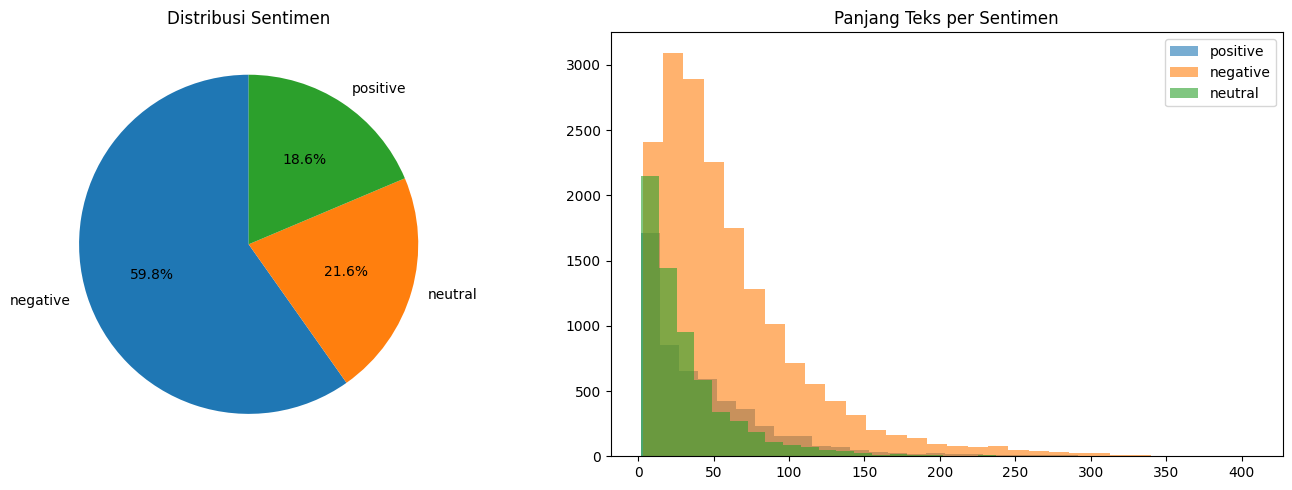

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
counts = clean_df['polarity'].value_counts()
axes[0].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Distribusi Sentimen')

# Bar chart panjang teks per sentimen
clean_df['text_len_final'] = clean_df['text_akhir'].apply(len)
for pol in ['positive','negative','neutral']:
    subset = clean_df[clean_df['polarity'] == pol]['text_len_final']
    axes[1].hist(subset, alpha=0.6, label=pol, bins=30)
axes[1].set_title('Panjang Teks per Sentimen')
axes[1].legend()

plt.tight_layout()
plt.show()

# Simpan data bersih
finaldf = clean_df[['text_akhir', 'polarity']]
finaldf.to_csv(os.path.join(save_path, 'clean_data.csv'), index=False)

## Setup Data Fitur dan Target

In [11]:
X = clean_df['text_akhir']
y = clean_df['polarity']

print(f'Total sampel: {len(X)}')
print('Distribusi kelas:')
print(y.value_counts())

Total sampel: 29634
Distribusi kelas:
polarity
negative    17718
neutral      6393
positive     5523
Name: count, dtype: int64


## Skema 1: Logistic Regression

**Strategi peningkatan:**
1. Kombinasi TF-IDF word n-gram (1–3) dan char n-gram (3–5) sebagai representasi fitur
2. Perluasan ruang pencarian hyperparameter (solver lbfgs dan saga, variasi nilai C)
3. Oversampling menggunakan RandomOverSampler untuk menangani ketidakseimbangan kelas
4. Validasi silang 5-fold dengan StratifiedKFold
5. Split data latih dan uji: 70:30

In [12]:
from sklearn.pipeline import FeatureUnion

# Split 70:30 dengan stratifikasi
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

print(f'Train: {len(X_train_lr)}, Test: {len(X_test_lr)}')
print('Distribusi train:', y_train_lr.value_counts().to_dict())

Train: 20743, Test: 8891
Distribusi train: {'negative': 12402, 'neutral': 4475, 'positive': 3866}


In [13]:
# ── TF-IDF WORD n-gram ──
tfidf_word = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 3),   # unigram, bigram, trigram
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    analyzer='word'
)

# ── TF-IDF CHAR n-gram (menangkap morfologi) ──
tfidf_char = TfidfVectorizer(
    max_features=10000,
    ngram_range=(3, 5),   # char trigram-pentagram
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
    analyzer='char_wb'
)

from scipy.sparse import hstack

# Fit + transform
X_train_word = tfidf_word.fit_transform(X_train_lr)
X_test_word  = tfidf_word.transform(X_test_lr)

X_train_char = tfidf_char.fit_transform(X_train_lr)
X_test_char  = tfidf_char.transform(X_test_lr)

# Gabungkan word + char features
X_train_combined = hstack([X_train_word, X_train_char])
X_test_combined  = hstack([X_test_word, X_test_char])

print(f'Dimensi fitur gabungan: {X_train_combined.shape}')

Dimensi fitur gabungan: (20743, 30000)


In [14]:
# Oversampling dengan RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_res, y_train_res = ros.fit_resample(X_train_combined, y_train_lr)

print('Distribusi setelah oversampling:')
from collections import Counter
print(Counter(y_train_res))

Distribusi setelah oversampling:
Counter({'positive': 12402, 'neutral': 12402, 'negative': 12402})


Fitting 5 folds for each of 12 candidates, totalling 60 fits

=== LOGISTIC REGRESSION ===
Best Params: {'C': 50, 'penalty': 'l2', 'solver': 'lbfgs'}
Accuracy: 0.8925 (89.25%)
              precision    recall  f1-score   support

    negative       0.95      0.95      0.95      5316
     neutral       0.76      0.78      0.77      1918
    positive       0.87      0.85      0.86      1657

    accuracy                           0.89      8891
   macro avg       0.86      0.86      0.86      8891
weighted avg       0.89      0.89      0.89      8891



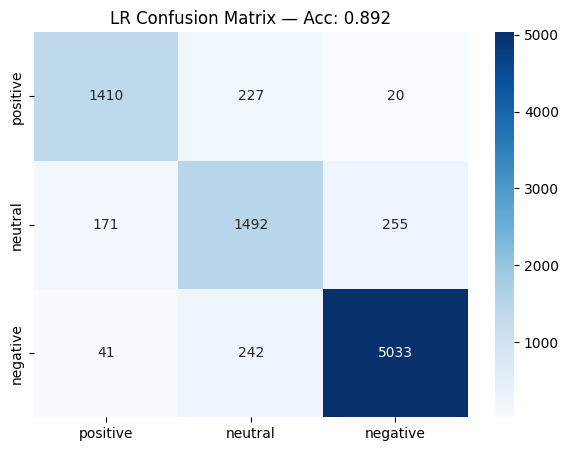

In [15]:
# Grid Search Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight='balanced')

param_lr = {
    'C': [0.01, 0.1, 1, 5, 10, 50],
    'solver': ['lbfgs', 'saga'],
    'penalty': ['l2']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(
    lr, param_lr,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_lr.fit(X_train_res, y_train_res)

best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_combined)
acc_lr = accuracy_score(y_test_lr, y_pred_lr)

print('\n=== LOGISTIC REGRESSION ===')
print('Best Params:', grid_lr.best_params_)
print(f'Accuracy: {acc_lr:.4f} ({acc_lr*100:.2f}%)')
print(classification_report(y_test_lr, y_pred_lr))

# Confusion matrix
cm = confusion_matrix(y_test_lr, y_pred_lr, labels=['positive','neutral','negative'])
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['positive','neutral','negative'],
            yticklabels=['positive','neutral','negative'], cmap='Blues')
plt.title(f'LR Confusion Matrix — Acc: {acc_lr:.3f}')
plt.show()

In [16]:
# Simpan model LR
joblib.dump(best_lr,   os.path.join(save_path, 'model_lr_optimized.pkl'))
joblib.dump(tfidf_word, os.path.join(save_path, 'tfidf_word_lr.pkl'))
joblib.dump(tfidf_char, os.path.join(save_path, 'tfidf_char_lr.pkl'))

['/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen/tfidf_char_lr.pkl']

## Skema 2: SVM — Optimized

**Strategi peningkatan:**
1. Kombinasi TF-IDF word n-gram dan char n-gram (konsisten dengan Skema 1)
2. LinearSVC dengan pembobotan kelas (class_weight='balanced')
3. Pencarian hyperparameter C secara granular (7 nilai: 0.01–100)
4. Split data latih dan uji: 80:20

In [17]:
# SVM memakai split 80:20
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# TF-IDF word
tfidf_word_svm = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    analyzer='word'
)

# TF-IDF char
tfidf_char_svm = TfidfVectorizer(
    max_features=10000,
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
    analyzer='char_wb'
)

X_train_word_svm = tfidf_word_svm.fit_transform(X_train_svm)
X_test_word_svm  = tfidf_word_svm.transform(X_test_svm)
X_train_char_svm = tfidf_char_svm.fit_transform(X_train_svm)
X_test_char_svm  = tfidf_char_svm.transform(X_test_svm)

X_train_comb_svm = hstack([X_train_word_svm, X_train_char_svm])
X_test_comb_svm  = hstack([X_test_word_svm, X_test_char_svm])

# Oversampling
ros_svm = RandomOverSampler(random_state=42)
X_train_res_svm, y_train_res_svm = ros_svm.fit_resample(X_train_comb_svm, y_train_svm)

print(f'Fitur SVM: {X_train_comb_svm.shape}')
print('Distribusi setelah oversampling:', Counter(y_train_res_svm))

Fitur SVM: (23707, 30000)
Distribusi setelah oversampling: Counter({'neutral': 14174, 'negative': 14174, 'positive': 14174})


Fitting 5 folds for each of 7 candidates, totalling 35 fits

=== SVM ===
Best Params: {'C': 5}
Accuracy: 0.8762 (87.62%)
              precision    recall  f1-score   support

    negative       0.93      0.95      0.94      3544
     neutral       0.75      0.68      0.72      1279
    positive       0.84      0.87      0.85      1104

    accuracy                           0.88      5927
   macro avg       0.84      0.83      0.83      5927
weighted avg       0.87      0.88      0.87      5927



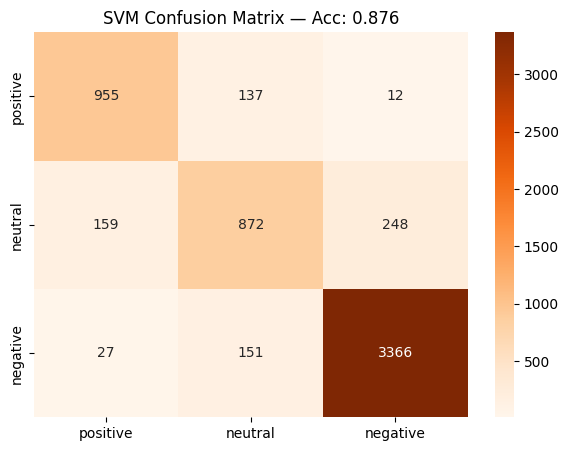

In [18]:
svm = LinearSVC(class_weight='balanced', max_iter=3000, dual=False)

param_svm = {'C': [0.01, 0.1, 1, 5, 10, 50, 100]}

grid_svm = GridSearchCV(
    svm, param_svm,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_svm.fit(X_train_res_svm, y_train_res_svm)

best_svm = grid_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_comb_svm)
acc_svm = accuracy_score(y_test_svm, y_pred_svm)

print('\n=== SVM ===')
print('Best Params:', grid_svm.best_params_)
print(f'Accuracy: {acc_svm:.4f} ({acc_svm*100:.2f}%)')
print(classification_report(y_test_svm, y_pred_svm))

cm = confusion_matrix(y_test_svm, y_pred_svm, labels=['positive','neutral','negative'])
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['positive','neutral','negative'],
            yticklabels=['positive','neutral','negative'], cmap='Oranges')
plt.title(f'SVM Confusion Matrix — Acc: {acc_svm:.3f}')
plt.show()

In [19]:
joblib.dump(best_svm,      os.path.join(save_path, 'model_svm_optimized.pkl'))
joblib.dump(tfidf_word_svm, os.path.join(save_path, 'tfidf_word_svm.pkl'))
joblib.dump(tfidf_char_svm, os.path.join(save_path, 'tfidf_char_svm.pkl'))

['/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen/tfidf_char_svm.pkl']

## Skema 3: BiLSTM — Optimized

**Strategi peningkatan:**
1. Dua lapis Bidirectional LSTM (64 unit pada lapis pertama, 32 unit pada lapis kedua)
2. Representasi gabungan GlobalAveragePooling dan GlobalMaxPooling untuk menangkap fitur global
3. Normalisasi antarlapis menggunakan LayerNormalization
4. Regularisasi label menggunakan label smoothing (nilai 0.1)
5. Penyesuaian learning rate adaptif menggunakan ReduceLROnPlateau
6. Panjang sekuens maksimum: 150 token
7. Split 80 data latih : 20 data uji

In [20]:
# Split 80:20
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Label encoding
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train_lstm)
y_test_enc  = label_encoder.transform(y_test_lstm)
num_classes = len(label_encoder.classes_)

print('Kelas:', label_encoder.classes_)
print('Distribusi train:', np.bincount(y_train_enc))

y_train_cat = to_categorical(y_train_enc, num_classes)
y_test_cat  = to_categorical(y_test_enc, num_classes)

Kelas: ['negative' 'neutral' 'positive']
Distribusi train: [14174  5114  4419]


In [21]:
# Tokenizer dengan vocab lebih besar
max_words = 15000
max_len   = 150

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_lstm)

X_train_seq = tokenizer.texts_to_sequences(X_train_lstm)
X_test_seq  = tokenizer.texts_to_sequences(X_test_lstm)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad  = pad_sequences(X_test_seq,  maxlen=max_len, padding='post', truncating='post')

print(f'Vocab size: {max_words}')
print(f'Max sequence length: {max_len}')
print(f'Train shape: {X_train_pad.shape}, Test shape: {X_test_pad.shape}')

Vocab size: 15000
Max sequence length: 150
Train shape: (23707, 150), Test shape: (5927, 150)


In [22]:
# Class weight
class_weights_arr = compute_class_weight('balanced', classes=np.unique(y_train_enc), y=y_train_enc)
class_weight_dict = dict(enumerate(class_weights_arr))
print('Class weights:', class_weight_dict)

Class weights: {0: np.float64(0.5575231644795635), 1: np.float64(1.545235301785947), 2: np.float64(1.7882628045560836)}


In [23]:
# ── ARSITEKTUR: BiLSTM + GlobalMaxPool + GlobalAvgPool (Capsule-style fusion) ──

def build_lstm_model(vocab_size, embed_dim, max_len, num_classes, lstm_units=64, dropout_rate=0.4):
    inp = Input(shape=(max_len,))

    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inp)
    x = Dropout(dropout_rate)(x)

    # Lapis BiLSTM pertama (return_sequences=True agar bisa stack)
    x = Bidirectional(LSTM(lstm_units, return_sequences=True, dropout=0.3, recurrent_dropout=0.1))(x)
    x = LayerNormalization()(x)

    # Lapis BiLSTM kedua
    x = Bidirectional(LSTM(lstm_units // 2, return_sequences=True, dropout=0.3, recurrent_dropout=0.1))(x)

    # Attention dengan GlobalMaxPool dan GlobalAvgPool — tangkap fitur penting
    avg_pool = GlobalAveragePooling1D()(x)
    max_pool = GlobalMaxPooling1D()(x)

    # Gabungkan kedua representasi
    concat = Concatenate()([avg_pool, max_pool])

    # Dense layers
    x = Dense(128, activation='relu', kernel_regularizer=l2(1e-4))(concat)
    x = Dropout(dropout_rate)(x)
    x = Dense(64, activation='relu', kernel_regularizer=l2(1e-4))(x)
    x = Dropout(dropout_rate / 2)(x)

    out = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inp, outputs=out)
    return model

model_lstm = build_lstm_model(
    vocab_size=max_words,
    embed_dim=128,
    max_len=max_len,
    num_classes=num_classes,
    lstm_units=64,
    dropout_rate=0.4
)
model_lstm.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │  1,920,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 150, 128)  │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 150, 128)  │     98,816 │ dropout[0][0]     │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 150, 128)  │        256 │ bidirectional[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 150, 64)   │     41,216 │ layer_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ bidirectional_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ bidirectional_1[… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3)         │        195 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,085,251 (7.95 MB)

 Trainable params: 2,085,251 (7.95 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# Compile dengan label smoothing (mengurangi overconfidence)
model_lstm.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    optimizer=Adam(learning_rate=5e-4),
    metrics=['accuracy']
)

# Callbacks
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=6,
    restore_best_weights=True,
    mode='max'
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

ckpt_path = os.path.join(save_path, 'best_lstm.keras')
model_ckpt = ModelCheckpoint(
    ckpt_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=0
)


In [25]:
# Training model
history = model_lstm.fit(
    X_train_pad, y_train_cat,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    callbacks=[early_stop, lr_scheduler, model_ckpt],
    verbose=1
)

Epoch 1/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 311s 879ms/step - accuracy: 0.6093 - loss: 0.9342 - val_accuracy: 0.8739 - val_loss: 0.5575 - learning_rate: 5.0000e-04
Epoch 2/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 317s 864ms/step - accuracy: 0.8558 - loss: 0.6079 - val_accuracy: 0.9013 - val_loss: 0.4832 - learning_rate: 5.0000e-04
Epoch 3/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 325s 873ms/step - accuracy: 0.9057 - loss: 0.5136 - val_accuracy: 0.9161 - val_loss: 0.4607 - learning_rate: 5.0000e-04
Epoch 4/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 326s 886ms/step - accuracy: 0.9229 - loss: 0.4724 - val_accuracy: 0.9245 - val_loss: 0.4542 - learning_rate: 5.0000e-04
Epoch 5/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 292s 875ms/step - accuracy: 0.9382 - loss: 0.4378 - val_accuracy: 0.9262 - val_loss: 0.4520 - learning_rate: 5.0000e-04
Epoch 6/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 327s 890ms/step - accuracy: 0.9472 - loss: 0.4209 - val_accuracy: 0.9304 - val_loss: 0.4443 - learning_rate: 5.0000e-04
Epoch 7/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 

186/186 ━━━━━━━━━━━━━━━━━━━━ 25s 128ms/step

=== BiLSTM ===
Accuracy: 0.9323 (93.23%)
              precision    recall  f1-score   support

    negative       0.97      0.96      0.96      3544
     neutral       0.83      0.87      0.85      1279
    positive       0.94      0.91      0.93      1104

    accuracy                           0.93      5927
   macro avg       0.91      0.91      0.91      5927
weighted avg       0.93      0.93      0.93      5927



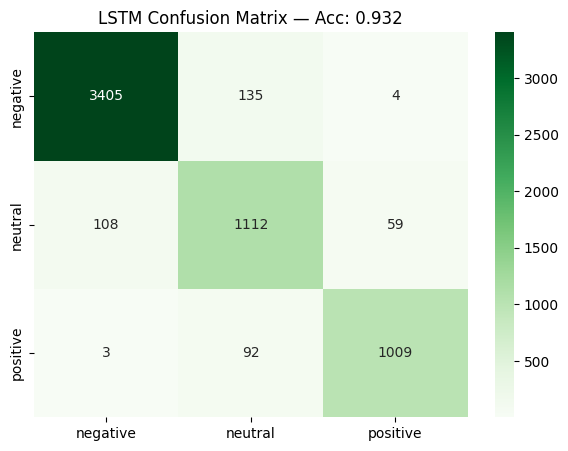

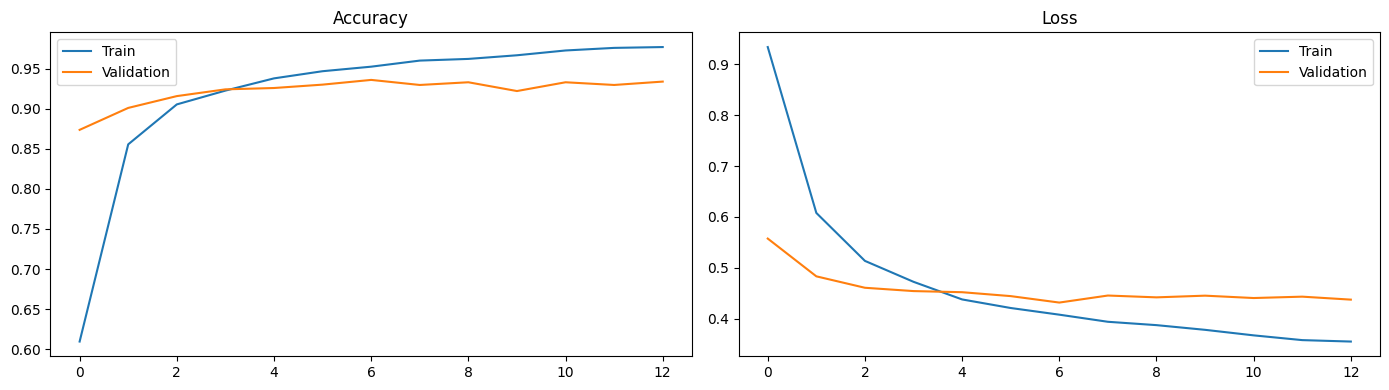

In [26]:
# Evaluasi LSTM
loss_lstm, acc_lstm = model_lstm.evaluate(X_test_pad, y_test_cat, verbose=0)

y_pred_lstm = np.argmax(model_lstm.predict(X_test_pad), axis=1)
y_true_lstm = y_test_enc

print('\n=== BiLSTM ===')
print(f'Accuracy: {acc_lstm:.4f} ({acc_lstm*100:.2f}%)')
print(classification_report(y_true_lstm, y_pred_lstm, target_names=label_encoder.classes_))

cm = confusion_matrix(y_true_lstm, y_pred_lstm)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, cmap='Greens')
plt.title(f'LSTM Confusion Matrix — Acc: {acc_lstm:.3f}')
plt.show()

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

In [27]:
# Simpan model LSTM
model_lstm.save(os.path.join(save_path, 'model_lstm_optimized.h5'))
joblib.dump(tokenizer,     os.path.join(save_path, 'tokenizer_lstm_optimized.pkl'))
joblib.dump(label_encoder, os.path.join(save_path, 'label_encoder_optimized.pkl'))

['/content/drive/MyDrive/DBS Coding Camp AI Engineer 2026/Analisis sentimen/label_encoder_optimized.pkl']

---
## Perbandingan Hasil Semua Model


=== PERBANDINGAN AKURASI ===
                      Model  Accuracy Status  Accuracy (%)
 BiLSTM + Attention (80:20)  0.932343 ✅ ≥85%         93.23
Logistic Regression (70:30)  0.892476 ✅ ≥85%         89.25
      SVM LinearSVC (80:20)  0.876160 ✅ ≥85%         87.62


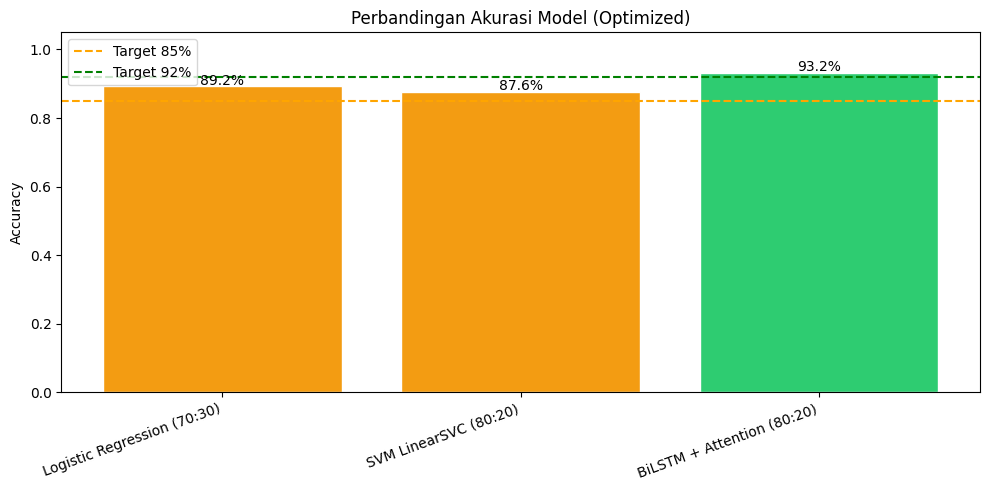

In [28]:
results_df = pd.DataFrame({
    'Model': [
        'Logistic Regression (70:30)',
        'SVM LinearSVC (80:20)',
        'BiLSTM + Attention (80:20)',
    ],
    'Accuracy': [acc_lr, acc_svm, acc_lstm],
    'Status': [
        '✅ ≥85%' if acc_lr >= 0.85 else '❌ <85%',
        '✅ ≥85%' if acc_svm >= 0.85 else '❌ <85%',
        '✅ ≥85%' if acc_lstm >= 0.85 else '❌ <85%',
    ]
})

results_df['Accuracy (%)'] = (results_df['Accuracy'] * 100).round(2)
print('\n=== PERBANDINGAN AKURASI ===')
print(results_df.sort_values('Accuracy', ascending=False).to_string(index=False))

# Bar chart
colors = ['#2ecc71' if a >= 0.92 else '#f39c12' if a >= 0.85 else '#e74c3c'
          for a in results_df['Accuracy']]

plt.figure(figsize=(10, 5))
bars = plt.bar(results_df['Model'], results_df['Accuracy'], color=colors, edgecolor='white')
plt.axhline(y=0.85, color='orange', linestyle='--', label='Target 85%')
plt.axhline(y=0.92, color='green',  linestyle='--', label='Target 92%')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{bar.get_height()*100:.1f}%', ha='center', fontsize=10)
plt.xticks(rotation=20, ha='right')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.title('Perbandingan Akurasi Model (Optimized)')
plt.legend()
plt.tight_layout()
plt.show()